In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [3]:
num_cols = ['floor_area_sqm', 'lease_commence_date']
cat_cols = ['month', 'town', 'flat_type', 'street_name', 'storey_range', 'flat_model', 'remaining_lease']

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('cat', cat_pipeline, cat_cols),
    ('num', num_pipeline, num_cols)
])

df = pd.read_csv("/Users/amel/Projects/HDBPredictor/data.csv")
X = df.drop(columns=["resale_price", "block"])
y = df["resale_price"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [ ]:
params = {
    "objective": "reg:squarederror",
    "max_depth": 4,
    "learning_rate": 0.9,
    "n_estimators": 1000,
    "reg_alpha": 10
}


pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(**params))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

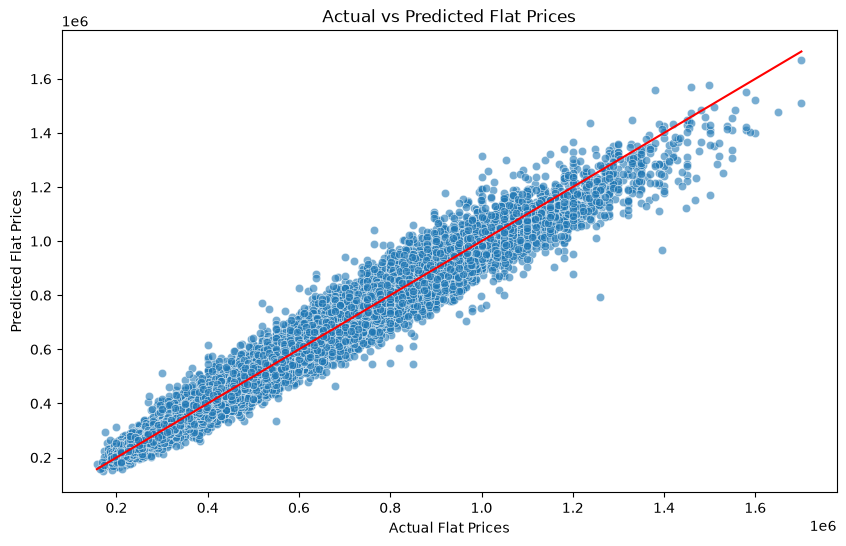

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red')
plt.title('Actual vs Predicted Flat Prices')
plt.xlabel('Actual Flat Prices')
plt.ylabel('Predicted Flat Prices')
plt.show()